In [1]:
# import torch
# import transformers

# print("Torch:", torch.__version__)
# print("Transformers:", transformers.__version__)


In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
# from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix, classification_report

import seaborn as sns
import matplotlib.pyplot as plt
import pickle

D:\BERT_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
from huggingface_hub import login



In [ ]:
from transformers import AlbertTokenizer, AutoModel
import subprocess
import sys
import importlib.util



model_name = "ai4bharat/indic-bert"
hf_token = os.getenv("HF_TOKEN")

# Use AlbertTokenizer (slow tokenizer) directly instead of AutoTokenizer
tokenizer = AlbertTokenizer.from_pretrained(
    model_name,
    token=hf_token
)

base_model = AutoModel.from_pretrained(
    model_name,
    token=hf_token
)

print("Model Loaded Successfully")

Model Loaded Successfully


In [5]:
train_df = pd.read_csv("train/train.csv")
dev_df = pd.read_csv("dev/dev.csv")
test_df = pd.read_csv("test/test.csv")

In [6]:
def preprocess(df):
    df["text"] = (
        df["complaint_title"].astype(str) + " " +
        df["text_en"].astype(str) + " " +
        df["Hindi"].astype(str) + " " +
        df["Hinglish"].astype(str)
    )

    df = df.dropna(subset=[
        "text", "category_primary",
        "category_secondary", "severity"
    ])

    return df.reset_index(drop=True)

train_df = preprocess(train_df)
dev_df = preprocess(dev_df)
test_df = preprocess(test_df)

train_df.head()

,original_id,Complain_date,complaint_title,text_en,location_address,category_primary,category_secondary,resolution_status,comment_count,Hindi,Hinglish,severity,severity_score,high_keywords_matched,medium_keywords_matched,text
0,BBMP_008791,03-08-2020 13:41,Streetlights not working,Diagonal road connecting bendre circle and BBM...,Opposite govt nature cure hospital,Electricity,Streetlights & Public Lighting,Open,0,बेंद्रे सर्कल और बीबीएमपी योग हॉल को जोड़ने वा...,Bendre circle aur BBMP yoga hall ko jodnewali ...,MEDIUM,4,NaN,not working,Streetlights not working Diagonal road connect...
1,BBMP_004679,09-06-2019 07:21,This is in middle of the road,This is in middle of the road,NaN,Road & Transportation,Road Damage & Potholes,Resolved,2,यह सड़क के बीच में है।,Yeh sadak ke beech mein hai.,LOW,0,NaN,NaN,This is in middle of the road This is in middl...
2,BBMP_006119,10/31/2019 17:36,There is big hole on the road where people wil...,There is big hole on the road where people wil...,NaN,Road & Transportation,Road Damage & Potholes,Resolved,1,सड़क पर एक बड़ा गड्ढा है जहाँ लोग बहुत तेज़ी स...,Sadak par ek bada gaddha hai jahan log bahut t...,MEDIUM,3,NaN,issue,There is big hole on the road where people wil...
3,BBMP_000306,1/22/2019 19:00,A lot of garbage is accumulated on harlur road...,A lot of garbage is accumulated on harlur road...,NaN,Waste Management,Garbage Dumping & Black Spots,Re-opened,4,हरलूर रोड पर जलाशय के पास बहुत कचरा जमा हो गया...,Harlur Road par jalashay ke paas bahut kachra ...,LOW,0,NaN,NaN,A lot of garbage is accumulated on harlur road...
4,BBMP_008274,2/15/2020 16:35,Road clearing material is just left. This plac...,Road clearing material is just left. This plac...,NaN,Waste Management,Garbage Dumping & Black Spots,Resolved,1,सड़क साफ करने वाली सामग्री बस छोड़ दी गई है। इ...,Sadak saaf karne wali samagri bas chhod di gay...,LOW,0,NaN,NaN,Road clearing material is just left. This plac...


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7791 entries, 0 to 7790
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   original_id              7791 non-null   object
 1   Complain_date            7791 non-null   object
 2   complaint_title          7791 non-null   object
 3   text_en                  7791 non-null   object
 4   location_address         4211 non-null   object
 5   category_primary         7791 non-null   object
 6   category_secondary       7791 non-null   object
 7   resolution_status        7791 non-null   object
 8   comment_count            7791 non-null   int64 
 9   Hindi                    7791 non-null   object
 10  Hinglish                 7791 non-null   object
 11  severity                 7791 non-null   object
 12  severity_score           7791 non-null   int64 
 13  high_keywords_matched    1355 non-null   object
 14  medium_keywords_matched  2606 non-null  

In [8]:
le_primary = LabelEncoder()
le_subcat = LabelEncoder()
le_severity = LabelEncoder()

train_df["primary_label"] = le_primary.fit_transform(train_df["category_primary"])
train_df["subcat_label"] = le_subcat.fit_transform(train_df["category_secondary"])
train_df["severity_label"] = le_severity.fit_transform(train_df["severity"])

In [9]:
dev_df["primary_label"] = le_primary.transform(dev_df["category_primary"])
dev_df["subcat_label"] = le_subcat.transform(dev_df["category_secondary"])
dev_df["severity_label"] = le_severity.transform(dev_df["severity"])

test_df["primary_label"] = le_primary.transform(test_df["category_primary"])
test_df["subcat_label"] = le_subcat.transform(test_df["category_secondary"])
test_df["severity_label"] = le_severity.transform(test_df["severity"])

In [10]:
class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]

        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long)
        }

In [11]:
## Data Loader
train_dataset = ComplaintDataset(train_df, tokenizer)
dev_dataset = ComplaintDataset(dev_df, tokenizer)
test_dataset = ComplaintDataset(test_df, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=8)
test_loader = DataLoader(test_dataset, batch_size=8)

In [12]:
## Multitask Module
class MultiTaskModel(nn.Module):
    def __init__(self, base_model, n1, n2, n3):
        super().__init__()
        self.base = base_model
        hidden = base_model.config.hidden_size

        self.dropout = nn.Dropout(0.3)

        self.fc1 = nn.Linear(hidden, n1)
        self.fc2 = nn.Linear(hidden, n2)
        self.fc3 = nn.Linear(hidden, n3)

    def forward(self, input_ids, attention_mask):
        out = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0]

        x = self.dropout(cls)

        return self.fc1(x), self.fc2(x), self.fc3(x)

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MultiTaskModel(
    base_model,
    len(le_primary.classes_),
    len(le_subcat.classes_),
    len(le_severity.classes_)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

In [28]:
epochs = 10

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        y1 = batch["primary"].to(device)
        y2 = batch["subcat"].to(device)
        y3 = batch["severity"].to(device)

        p1, p2, p3 = model(input_ids, attention_mask)

        loss1 = criterion(p1, y1)
        loss2 = criterion(p2, y2)
        loss3 = criterion(p3, y3)

        loss = loss1 + loss2 + 0.5 * loss3

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss}")

Epoch 1, Loss: 1393.4720221161842
Epoch 2, Loss: 1392.3351711630821
Epoch 3, Loss: 1394.2748627662659
Epoch 4, Loss: 1394.00346621871
Epoch 5, Loss: 1391.2658667564392
Epoch 6, Loss: 1392.6331584453583
Epoch 7, Loss: 1393.3265022039413
Epoch 8, Loss: 1393.4174255728722
Epoch 9, Loss: 1394.3542382717133
Epoch 10, Loss: 1392.5326248407364


In [15]:
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch in dev_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        y1 = batch["primary"].cpu().numpy()

        p1, _, _ = model(input_ids, attention_mask)
        preds = torch.argmax(p1, dim=1).cpu().numpy()

        y_true.extend(y1)
        y_pred.extend(preds)

In [17]:
torch.save(model.state_dict(), "models/indic_multitask_model.pt")

pickle.dump(le_primary, open("models/le_primary.pkl", "wb"))
pickle.dump(le_subcat, open("models/le_subcat.pkl", "wb"))
pickle.dump(le_severity, open("models/le_severity.pkl", "wb"))

In [18]:
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=le_primary.classes_))

Classification Report:

                                     precision    recall  f1-score   support

                        Electricity       0.94      0.89      0.91       193
Encroachment & Illegal Construction       0.62      0.35      0.44        23
                Health & Sanitation       0.53      0.62      0.57        65
                             Others       0.83      0.69      0.75       131
                      Public Safety       0.00      0.00      0.00        17
              Road & Transportation       0.85      0.90      0.87       605
                   Waste Management       0.90      0.91      0.90       487
                      Water Leakage       0.83      0.88      0.86        34

                           accuracy                           0.85      1555
                          macro avg       0.69      0.65      0.66      1555
                       weighted avg       0.85      0.85      0.85      1555



D:\BERT_Project\bert_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\BERT_Project\bert_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\BERT_Project\bert_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


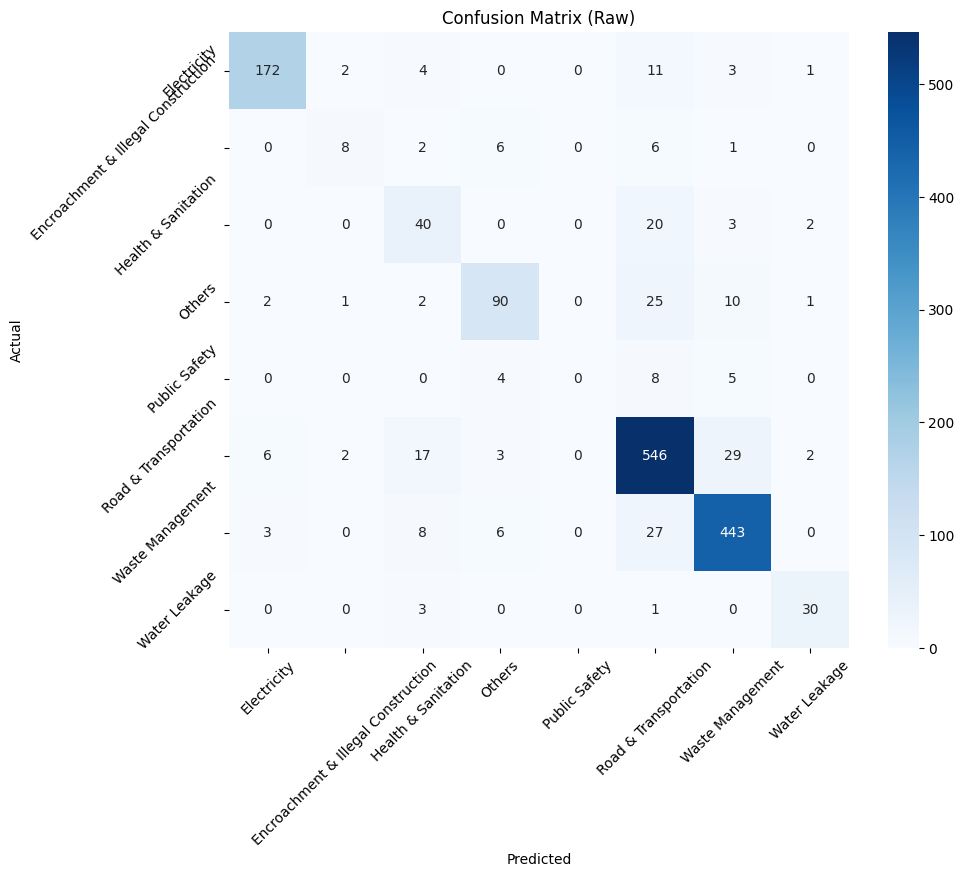

In [19]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_primary.classes_,
    yticklabels=le_primary.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Raw)")
plt.xticks(rotation=45)
plt.yticks(rotation=45)

plt.show()

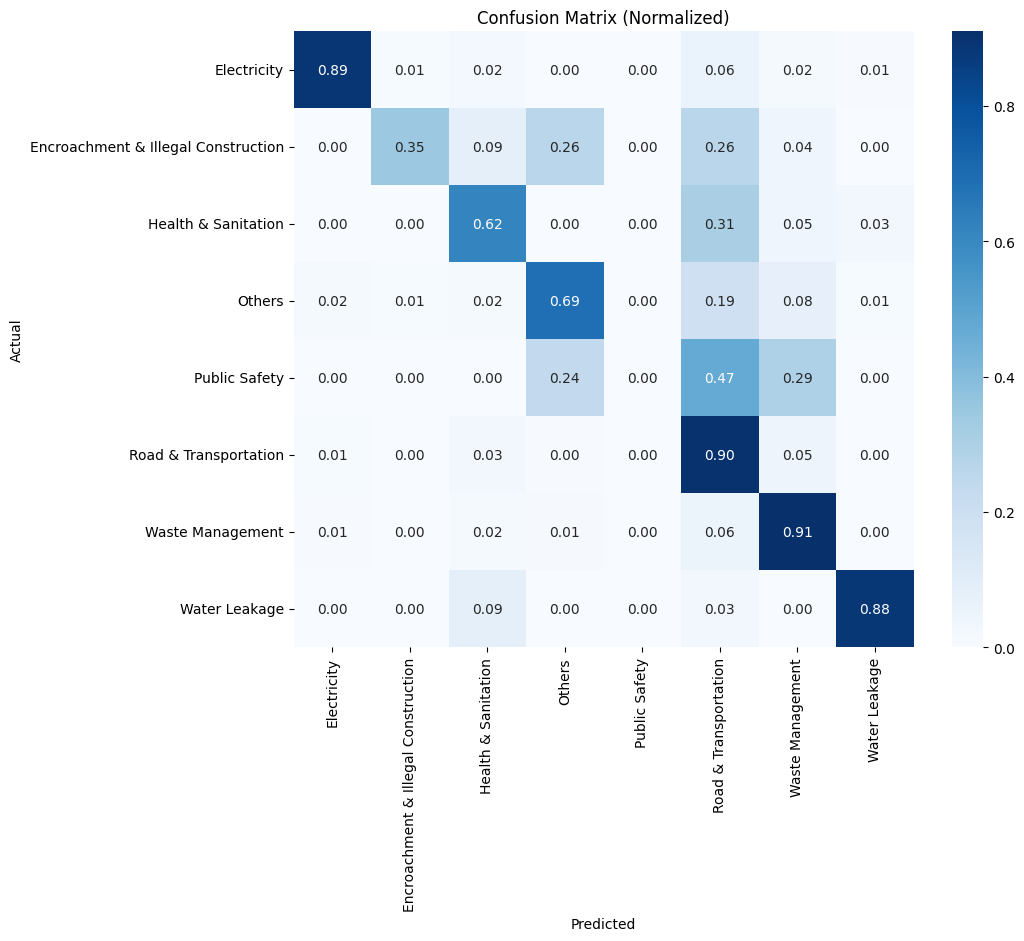

In [20]:
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap = "Blues",
    xticklabels=le_primary.classes_,
    yticklabels=le_primary.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Normalized)")
# plt.xticks(rotation=45)
# plt.yticks(rotation=45)

plt.show()

In [21]:
def predict(text):
    model.eval()

    enc = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)

    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    with torch.no_grad():
        p1, p2, p3 = model(input_ids, attention_mask)

    primary = le_primary.inverse_transform([torch.argmax(p1).item()])[0]
    subcat = le_subcat.inverse_transform([torch.argmax(p2).item()])[0]
    severity = le_severity.inverse_transform([torch.argmax(p3).item()])[0]

    return primary, subcat, severity

In [22]:
print(predict("Garbage not collected in my area from last 5 days"))

('Waste Management', 'Garbage Dumping & Black Spots', 'LOW')


In [23]:
predict("There is very big potholes in road near my society. And Yesterday two people got hurted due to the accident at that place")

('Road & Transportation', 'Road Damage & Potholes', 'MEDIUM')

In [24]:
predict("In my Area Transformer get blasted and no electricy it's very urgent fix it please. So Please fix it quickly. It's very hard to survive without electricity make it. Feel it very urgent and do it as soon as quickly")

('Electricity', 'Streetlights & Public Lighting', 'LOW')

In [25]:
predict("Huge Water Leakage in my Area near Vishnu chowk please fix it.")

('Road & Transportation', 'Road Damage & Potholes', 'LOW')

In [ ]:
# =====================
# HuggingFace Token
# =====================
HF_TOKEN = os.getenv("HF_TOKEN")  # 🔴 Replace with your token

In [27]:
import torch
import pickle
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel


# =====================
# Model Config
# =====================
model_name = "ai4bharat/indic-bert"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================
# Load Tokenizer
# =====================
tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    token=HF_TOKEN
)

# =====================
# Load Base Model (IMPORTANT)
# =====================
base_model = AutoModel.from_pretrained(
    model_name,
    token=HF_TOKEN
)

# =====================
# Model Definition
# =====================
class MultiTaskModel(nn.Module):
    def __init__(self, base_model, n1, n2, n3):
        super().__init__()
        self.base = base_model
        hidden = base_model.config.hidden_size

        self.dropout = nn.Dropout(0.3)

        self.fc1 = nn.Linear(hidden, n1)
        self.fc2 = nn.Linear(hidden, n2)
        self.fc3 = nn.Linear(hidden, n3)

    def forward(self, input_ids, attention_mask):
        out = self.base(input_ids=input_ids, attention_mask=attention_mask)

        # ✅ FIXED
        cls = out.last_hidden_state[:, 0, :]

        x = self.dropout(cls)

        return self.fc1(x), self.fc2(x), self.fc3(x)

# =====================
# Load Encoders
# =====================
le_primary = pickle.load(open("models/le_primary.pkl", "rb"))
le_subcat = pickle.load(open("models/le_subcat.pkl", "rb"))
le_severity = pickle.load(open("models/le_severity.pkl", "rb"))

# =====================
# Initialize Model
# =====================
model = MultiTaskModel(
    base_model,   # ✅ FIXED
    len(le_primary.classes_),
    len(le_subcat.classes_),
    len(le_severity.classes_)
)

# =====================
# Load Weights
# =====================
model.load_state_dict(torch.load("models/indic_multitask_model.pt", map_location=device))

model.to(device)
model.eval()

print("✅ IndicBERT Model Loaded Successfully")

# =====================
# Prediction Function
# =====================
def predict(text):
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding="max_length",
        max_length=128
    )

    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    with torch.no_grad():
        p1, p2, p3 = model(input_ids, attention_mask)

    return {
        "Primary": le_primary.inverse_transform([torch.argmax(p1).item()])[0],
        "Subcategory": le_subcat.inverse_transform([torch.argmax(p2).item()])[0],
        "Severity": le_severity.inverse_transform([torch.argmax(p3).item()])[0]
    }

# =====================
# Demo
# =====================
print(predict("Garbage not collected in my area for last 5 days"))

C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_16156\2812429129.py:74: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("models/indic_m

✅ IndicBERT Model Loaded Successfully
{'Primary': 'Waste Management', 'Subcategory': 'Garbage Dumping & Black Spots', 'Severity': 'LOW'}
